# 🦌 Exploración del Dataset Doñana 2024 — Observaciones con Cámaras Trampa

Este notebook analiza el archivo `observations.csv` del paquete de datos **dona_24**, que contiene registros de fauna silvestre capturados por cámaras trampa en el Parque Nacional de Doñana.

**Contenido:**
1. Carga y vista general del dataset
2. Distribución de especies (nombre científico → nombre común en español)
3. Análisis de conteos (count)
4. Análisis de confianza (classificationProbability)
5. Distribución temporal de las observaciones
6. Tipos de observación y métodos de clasificación
7. Análisis por cámara/despliegue

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 100
})

# Carga del dataset
df = pd.read_csv('dona_24/dona_24_pkg/observations.csv')
print(f'Filas: {len(df):,}  |  Columnas: {len(df.columns)}')
df.head(3)

Filas: 21,998  |  Columnas: 28


,observationID,deploymentID,mediaID,eventID,eventStart,eventEnd,observationLevel,observationType,cameraSetupType,scientificName,...,bboxX,bboxY,bboxWidth,bboxHeight,classificationMethod,classifiedBy,classificationTimestamp,classificationProbability,observationTags,observationComments
0,1,r0001-dona_0006,b515fccb-aa17-5aea-982e-c61ad37060c5,d1cb76e0-1983-483b-94b4-93d4ad5ab4e5,2020-10-24T13:10:59+0000,2020-10-24T13:10:59+0000,media,animal,NaN,Dama dama,...,NaN,NaN,NaN,NaN,human,zooniverse@wildintel-project.org,2026-07-07T17:28:34+0000,0.5,NaN,NaN
1,2,r0001-dona_0006,99347be5-a9a5-5872-b40a-d6e99041e4e7,d1cb76e0-1983-483b-94b4-93d4ad5ab4e5,2020-10-24T13:10:59+0000,2020-10-24T13:10:59+0000,media,animal,NaN,Cervus elaphus,...,NaN,NaN,NaN,NaN,human,zooniverse@wildintel-project.org,2026-07-07T17:28:34+0000,0.6,NaN,NaN
2,3,r0001-dona_0006,NaN,d1cb76e0-1983-483b-94b4-93d4ad5ab4e5,2020-10-24T13:10:59+0000,2020-10-24T13:10:59+0000,event,animal,NaN,Dama dama,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Vista general del dataset

In [2]:
print('--- Tipos de dato ---')
print(df.dtypes.to_string())
print()
print('--- Valores nulos por columna ---')
null_pct = (df.isnull().sum() / len(df) * 100).round(1)
print(null_pct[null_pct > 0].sort_values(ascending=False).to_string())

--- Tipos de dato ---
observationID                  int64
deploymentID                  object
mediaID                       object
eventID                       object
eventStart                    object
eventEnd                      object
observationLevel              object
observationType               object
cameraSetupType              float64
scientificName                object
count                          int64
lifeStage                    float64
sex                          float64
behavior                     float64
individualID                 float64
individualPositionRadius     float64
individualPositionAngle      float64
individualSpeed              float64
bboxX                        float64
bboxY                        float64
bboxWidth                    float64
bboxHeight                   float64
classificationMethod          object
classifiedBy                  object
classificationTimestamp       object
classificationProbability    float64
observationTags 

In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
observationID,21998.0,NaN,NaN,NaN,11329.888808,6531.300485,1.0,5737.25,11236.5,16972.75,22673.0
deploymentID,21998,37,r0001-dona_0021,6078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mediaID,19745,19616,1b18c6e3-b509-5b7a-b133-c0be52f976dc,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eventID,21998,1311,d37d6610-caae-477b-9e8e-829981490bf6,593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eventStart,21998,13827,2020-11-13T15:07:12+0000,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
eventEnd,21998,13827,2020-11-13T17:52:22+0000,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observationLevel,21998,2,media,19745,NaN,NaN,NaN,NaN,NaN,NaN,NaN
observationType,21998,3,animal,17209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cameraSetupType,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scientificName,16943,15,Cervidae,4618,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Distribución de especies — Nombres comunes en español

Mapeamos cada nombre científico a su nombre común en español.

In [4]:
# Diccionario nombre científico → nombre común en español
NOMBRE_COMUN = {
    'Cervus elaphus':          'Ciervo rojo',
    'Cervidae':                'Cérvido (sin especificar)',
    'Dama dama':               'Gamo',
    'Sus scrofa':              'Jabalí',
    'Bos taurus':              'Vaca / Toro',
    'Vulpes vulpes':           'Zorro rojo',
    'Leporidae':               'Lepórido (liebre/conejo)',
    'Oryctolagus cuniculus':   'Conejo europeo',
    'Meles meles':             'Tejón europeo',
    'Equus caballus':          'Caballo',
    'Lepus granatensis':       'Liebre ibérica',
    'Homo sapiens':            'Humano',
    'Herpestes ichneumon':     'Meloncillo',
    'Genetta genetta':         'Gineta',
    'Lynx pardinus':           'Lince ibérico',
}

df['nombre_comun'] = df['scientificName'].map(NOMBRE_COMUN).fillna('Desconocido')

# Tabla resumen
species_counts = (
    df[df['scientificName'].notna()]
    .groupby(['scientificName', 'nombre_comun'])
    .size()
    .reset_index(name='n_registros')
    .sort_values('n_registros', ascending=False)
    .reset_index(drop=True)
)
species_counts['porcentaje'] = (species_counts['n_registros'] / species_counts['n_registros'].sum() * 100).round(1)
species_counts

,scientificName,nombre_comun,n_registros,porcentaje
0,Cervidae,Cérvido (sin especificar),4618,27.3
1,Cervus elaphus,Ciervo rojo,4183,24.7
2,Sus scrofa,Jabalí,3558,21.0
3,Bos taurus,Vaca / Toro,2107,12.4
4,Dama dama,Gamo,874,5.2
5,Leporidae,Lepórido (liebre/conejo),518,3.1
6,Vulpes vulpes,Zorro rojo,474,2.8
7,Oryctolagus cuniculus,Conejo europeo,174,1.0
8,Meles meles,Tejón europeo,144,0.8
9,Equus caballus,Caballo,90,0.5


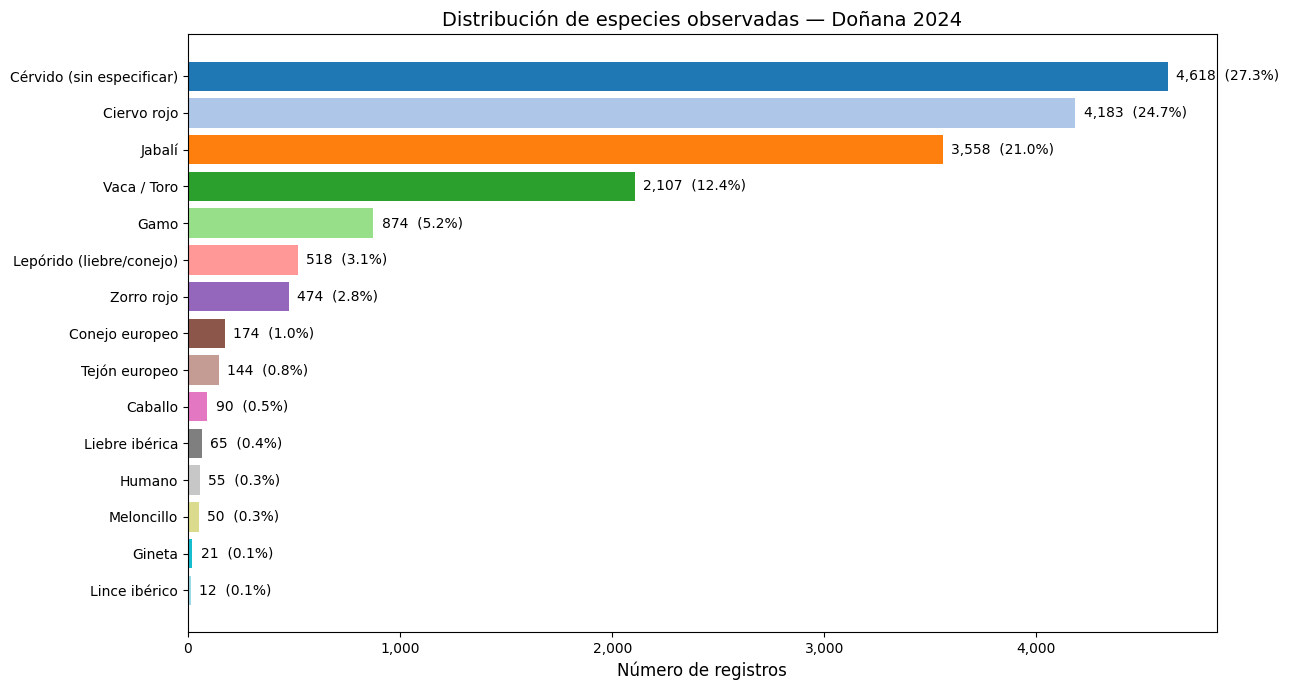

In [5]:
# Gráfico de barras — distribución de especies
fig, ax = plt.subplots(figsize=(13, 7))
colors = plt.cm.tab20(np.linspace(0, 1, len(species_counts)))

bars = ax.barh(
    species_counts['nombre_comun'],
    species_counts['n_registros'],
    color=colors
)

# Etiquetas con conteo y porcentaje
for bar, n, pct in zip(bars, species_counts['n_registros'], species_counts['porcentaje']):
    ax.text(bar.get_width() + 40, bar.get_y() + bar.get_height()/2,
            f'{n:,}  ({pct}%)', va='center', fontsize=10)

ax.set_xlabel('Número de registros')
ax.set_title('Distribución de especies observadas — Doñana 2024')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

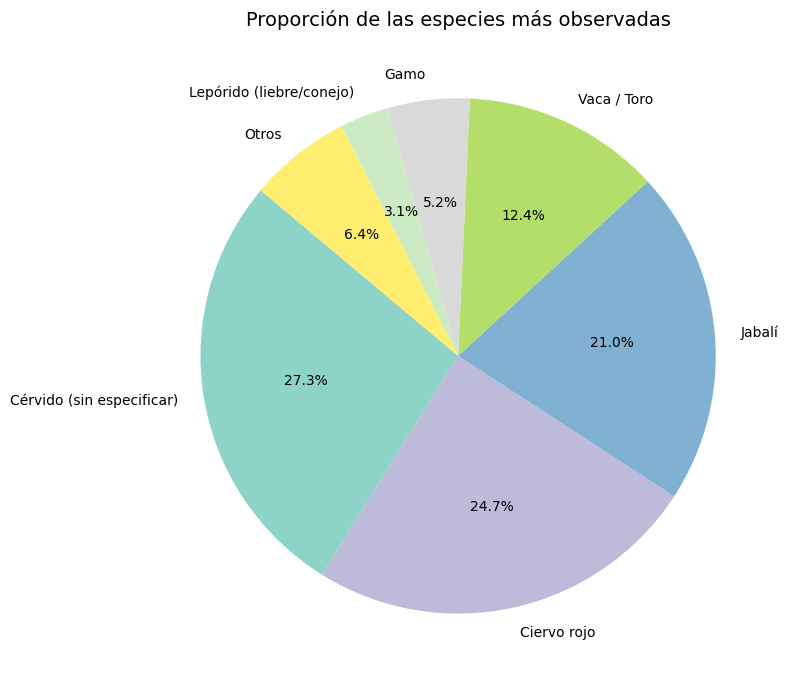

In [6]:
# Gráfico de tarta — Top 6 + Otros
top_n = 6
top = species_counts.head(top_n).copy()
otros = pd.DataFrame([{
    'nombre_comun': 'Otros',
    'n_registros': species_counts.iloc[top_n:]['n_registros'].sum()
}])
pie_data = pd.concat([top, otros], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    pie_data['n_registros'],
    labels=pie_data['nombre_comun'],
    autopct='%1.1f%%',
    startangle=140,
    colors=plt.cm.Set3(np.linspace(0, 1, len(pie_data)))
)
ax.set_title('Proporción de las especies más observadas')
plt.tight_layout()
plt.show()

## 3. Análisis de conteos (`count`)

In [7]:
df['count'] = pd.to_numeric(df['count'], errors='coerce')

print('--- Estadísticas del campo count ---')
print(df['count'].describe().to_string())
print(f"\nRegistros con count > 1: {(df['count'] > 1).sum()}")
print(f"Conteo máximo: {df['count'].max()}")

--- Estadísticas del campo count ---
count    21998.000000
mean         1.336303
std          0.776175
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          9.000000

Registros con count > 1: 4639
Conteo máximo: 9


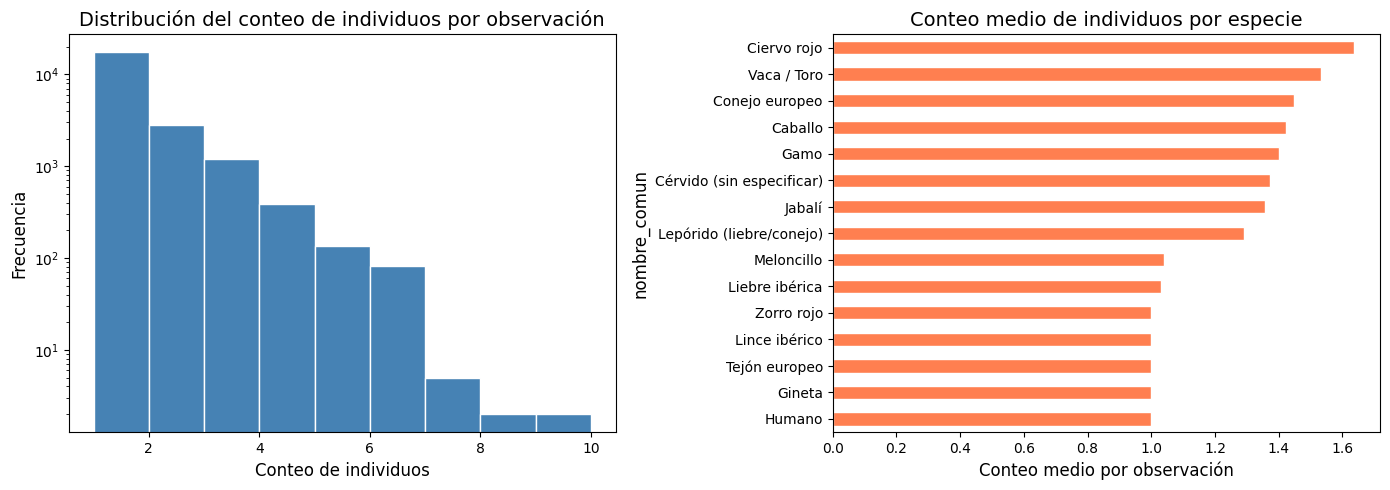

In [8]:
# Histograma del conteo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

counts_valid = df['count'].dropna()
axes[0].hist(counts_valid, bins=range(1, int(counts_valid.max())+2), color='steelblue', edgecolor='white')
axes[0].set_xlabel('Conteo de individuos')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribución del conteo de individuos por observación')
axes[0].set_yscale('log')

# Conteo medio por especie
mean_count = (
    df[df['scientificName'].notna()]
    .groupby('nombre_comun')['count']
    .mean()
    .sort_values(ascending=True)
)
mean_count.plot.barh(ax=axes[1], color='coral', edgecolor='white')
axes[1].set_xlabel('Conteo medio por observación')
axes[1].set_title('Conteo medio de individuos por especie')

plt.tight_layout()
plt.show()

## 4. Análisis de confianza (`classificationProbability`)

In [9]:
df['classificationProbability'] = pd.to_numeric(df['classificationProbability'], errors='coerce')

prob = df['classificationProbability'].dropna()
print('--- Estadísticas de classificationProbability ---')
print(prob.describe().to_string())
print(f"\nRegistros con probabilidad: {len(prob):,}")
print(f"Registros sin probabilidad: {df['classificationProbability'].isna().sum():,}")

--- Estadísticas de classificationProbability ---
count    19745.000000
mean         0.780527
std          0.169195
min          0.330000
25%          0.630000
50%          0.830000
75%          1.000000
max          1.000000

Registros con probabilidad: 19,745
Registros sin probabilidad: 2,253


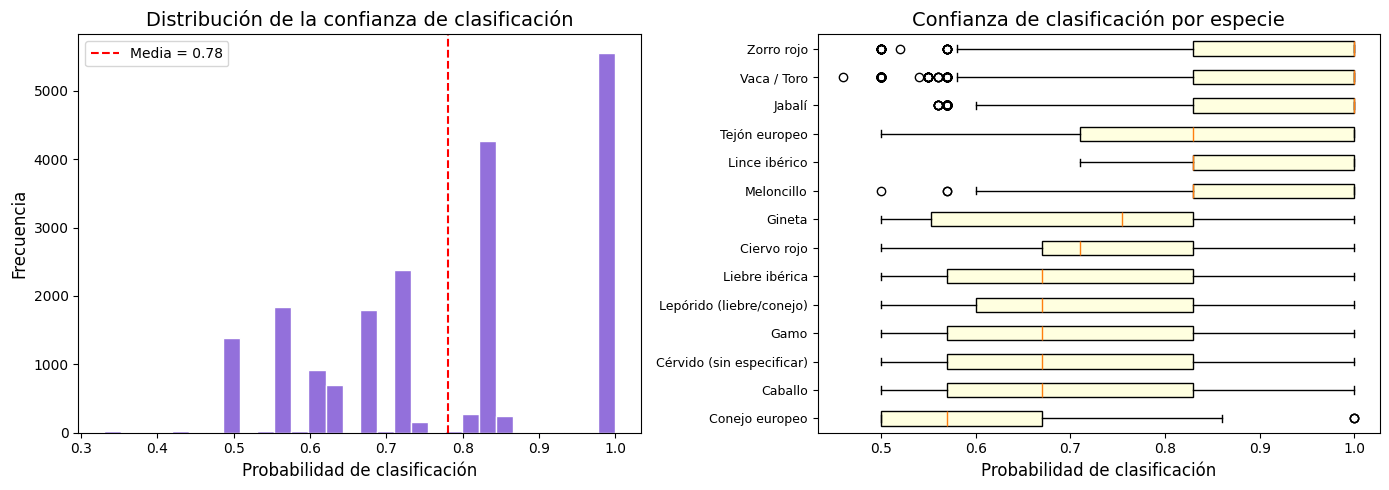

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de probabilidad
axes[0].hist(prob, bins=30, color='mediumpurple', edgecolor='white')
axes[0].set_xlabel('Probabilidad de clasificación')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribución de la confianza de clasificación')
axes[0].axvline(prob.mean(), color='red', linestyle='--', label=f'Media = {prob.mean():.2f}')
axes[0].legend()

# Boxplot de probabilidad por especie
species_with_prob = df[df['classificationProbability'].notna() & df['scientificName'].notna()]
order = species_with_prob.groupby('nombre_comun')['classificationProbability'].median().sort_values().index

data_for_box = [species_with_prob[species_with_prob['nombre_comun'] == sp]['classificationProbability'].values for sp in order]
bp = axes[1].boxplot(data_for_box, vert=False, patch_artist=True,
                     boxprops=dict(facecolor='lightyellow'))
axes[1].set_yticklabels(order, fontsize=9)
axes[1].set_xlabel('Probabilidad de clasificación')
axes[1].set_title('Confianza de clasificación por especie')

plt.tight_layout()
plt.show()

## 5. Distribución temporal de las observaciones

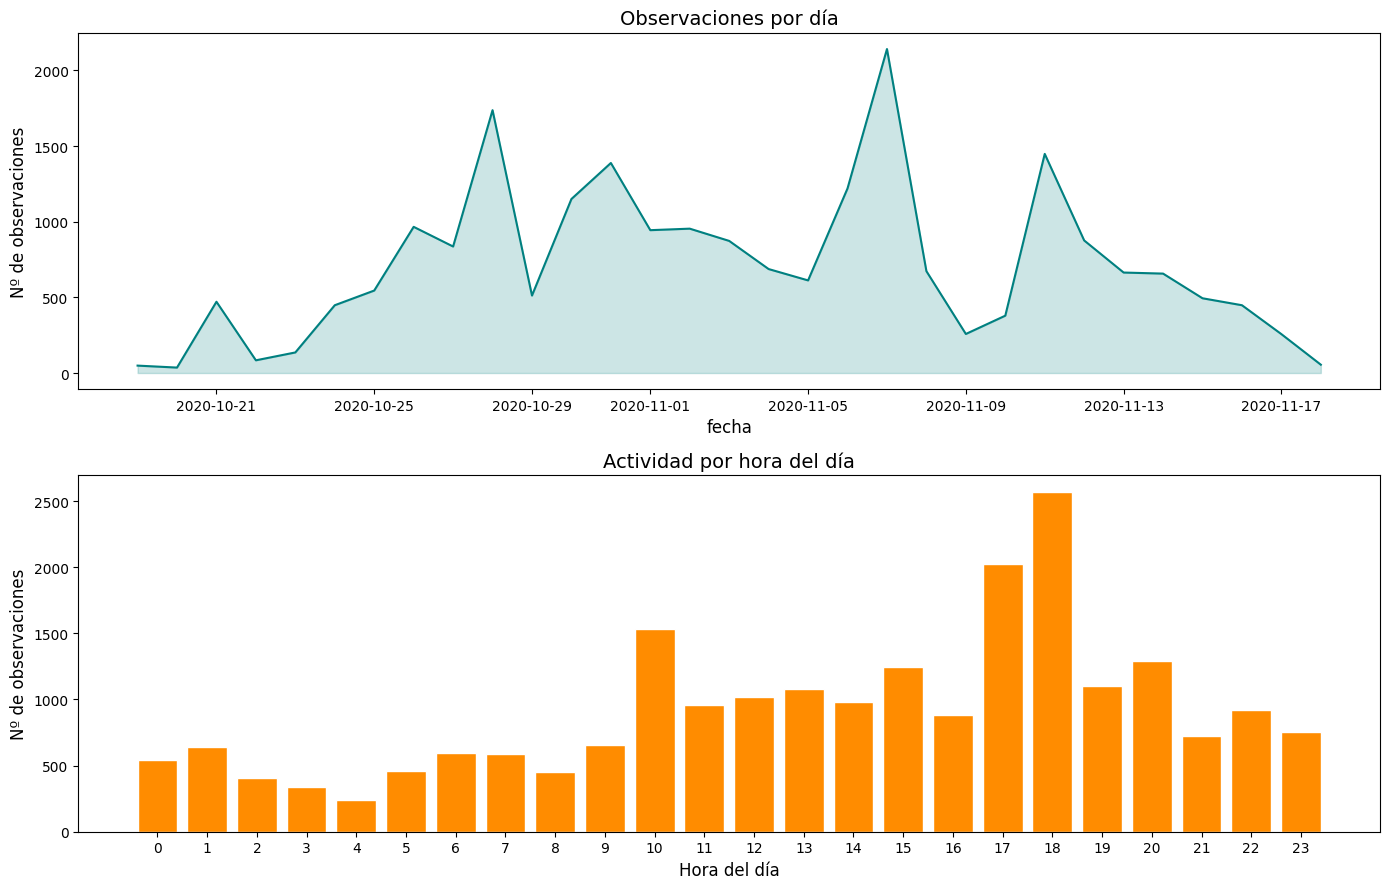

In [11]:
df['eventStart'] = pd.to_datetime(df['eventStart'], errors='coerce', utc=True)
df['fecha'] = df['eventStart'].dt.date
df['hora'] = df['eventStart'].dt.hour

# Observaciones por día
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

daily = df.groupby('fecha').size()
daily.plot(ax=axes[0], color='teal', linewidth=1.5)
axes[0].set_ylabel('Nº de observaciones')
axes[0].set_title('Observaciones por día')
axes[0].fill_between(daily.index, daily.values, alpha=0.2, color='teal')

# Observaciones por hora del día
hourly = df.groupby('hora').size()
axes[1].bar(hourly.index, hourly.values, color='darkorange', edgecolor='white')
axes[1].set_xlabel('Hora del día')
axes[1].set_ylabel('Nº de observaciones')
axes[1].set_title('Actividad por hora del día')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

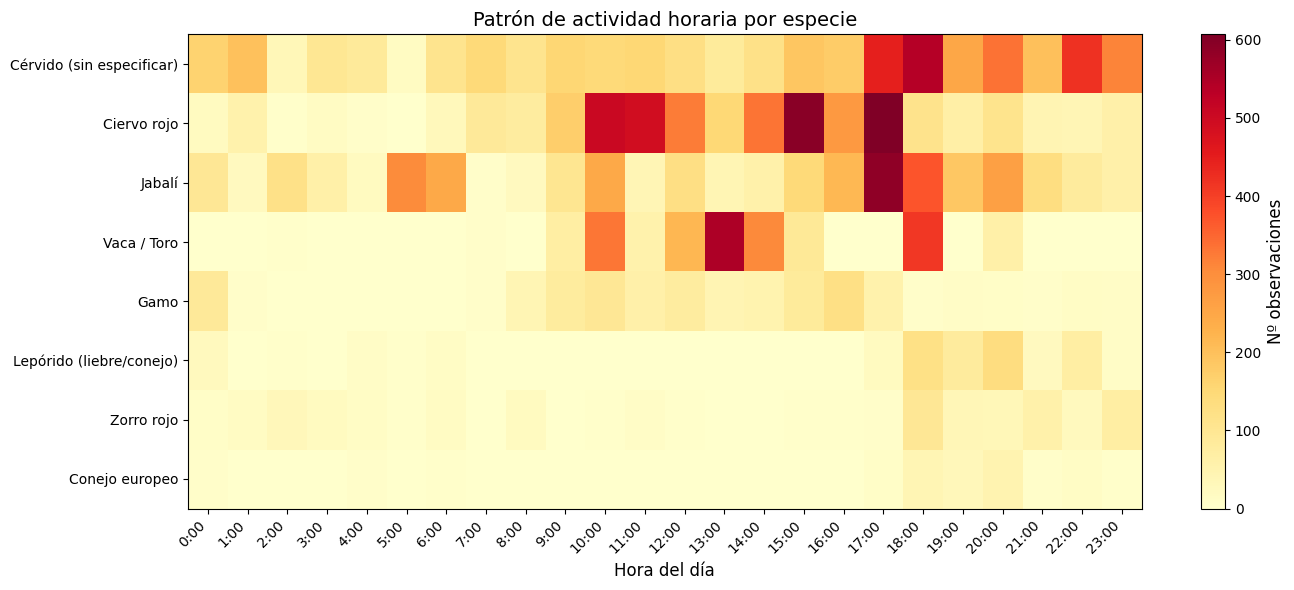

In [12]:
# Heatmap: actividad horaria por especie (top 8)
top_species = species_counts.head(8)['nombre_comun'].tolist()
subset = df[df['nombre_comun'].isin(top_species)].copy()

pivot = subset.groupby(['nombre_comun', 'hora']).size().unstack(fill_value=0)
pivot = pivot.reindex(top_species)  # mantener orden de abundancia

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='YlOrRd')
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xticks(range(24))
ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45, ha='right')
ax.set_xlabel('Hora del día')
ax.set_title('Patrón de actividad horaria por especie')
plt.colorbar(im, ax=ax, label='Nº observaciones')
plt.tight_layout()
plt.show()

## 6. Tipos de observación y métodos de clasificación

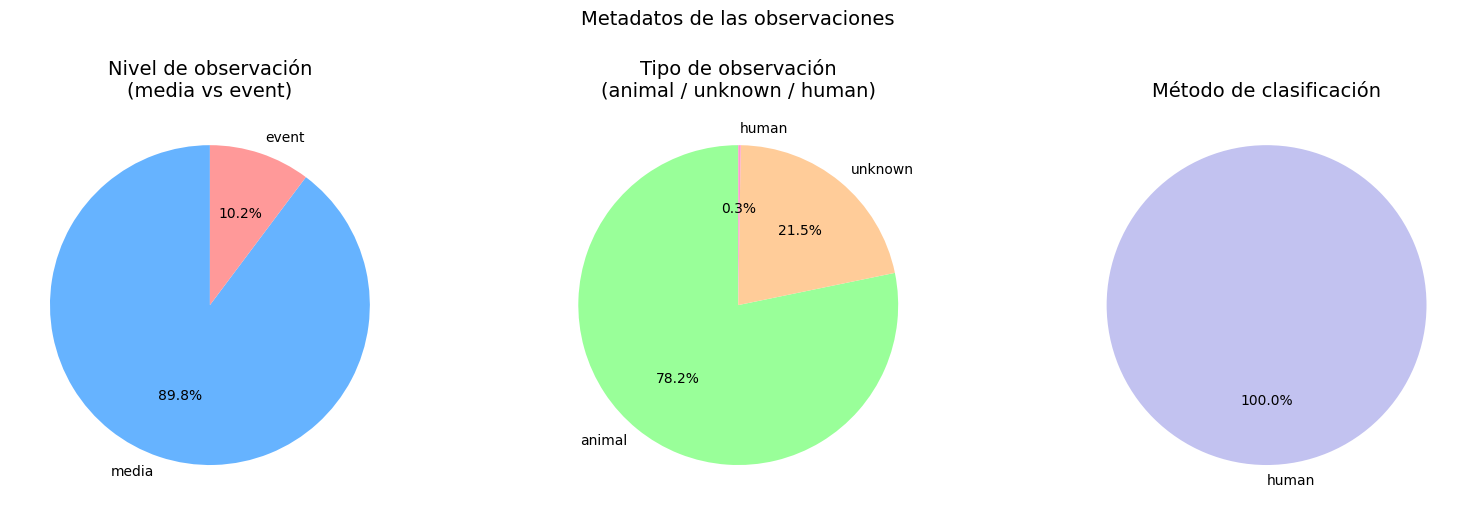

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# observationLevel
df['observationLevel'].value_counts().plot.pie(
    ax=axes[0], autopct='%1.1f%%', startangle=90,
    colors=['#66b3ff', '#ff9999'])
axes[0].set_ylabel('')
axes[0].set_title('Nivel de observación\n(media vs event)')

# observationType
df['observationType'].value_counts().plot.pie(
    ax=axes[1], autopct='%1.1f%%', startangle=90,
    colors=['#99ff99', '#ffcc99', '#ff99cc'])
axes[1].set_ylabel('')
axes[1].set_title('Tipo de observación\n(animal / unknown / human)')

# classificationMethod
df['classificationMethod'].value_counts().plot.pie(
    ax=axes[2], autopct='%1.1f%%', startangle=90,
    colors=['#c2c2f0', '#ffb3e6'])
axes[2].set_ylabel('')
axes[2].set_title('Método de clasificación')

plt.suptitle('Metadatos de las observaciones', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 7. Análisis por cámara / despliegue (`deploymentID`)

Número total de despliegues (cámaras): 37
Observaciones por cámara — media: 595, mediana: 198
Cámara con más registros: r0001-dona_0021 (6,078)


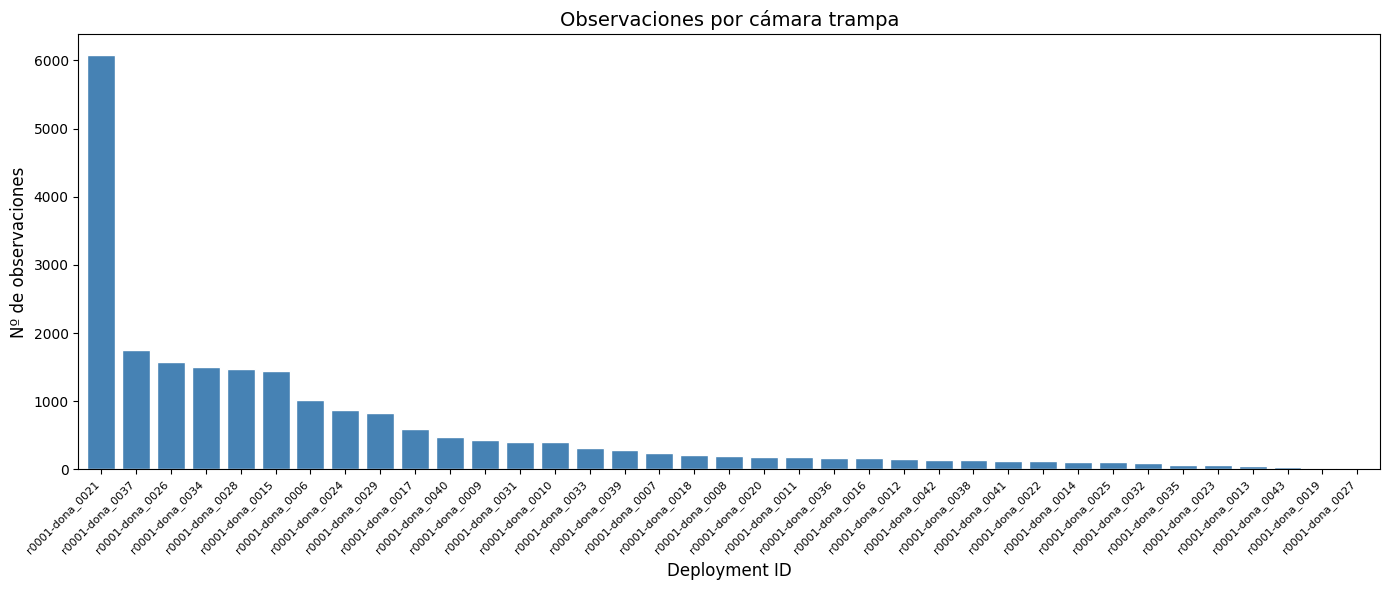

In [14]:
deploy_counts = df.groupby('deploymentID').size().sort_values(ascending=False)
print(f'Número total de despliegues (cámaras): {deploy_counts.shape[0]}')
print(f'Observaciones por cámara — media: {deploy_counts.mean():.0f}, mediana: {deploy_counts.median():.0f}')
print(f'Cámara con más registros: {deploy_counts.index[0]} ({deploy_counts.iloc[0]:,})')

fig, ax = plt.subplots(figsize=(14, 6))
deploy_counts.plot.bar(ax=ax, color='steelblue', edgecolor='white', width=0.8)
ax.set_ylabel('Nº de observaciones')
ax.set_xlabel('Deployment ID')
ax.set_title('Observaciones por cámara trampa')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

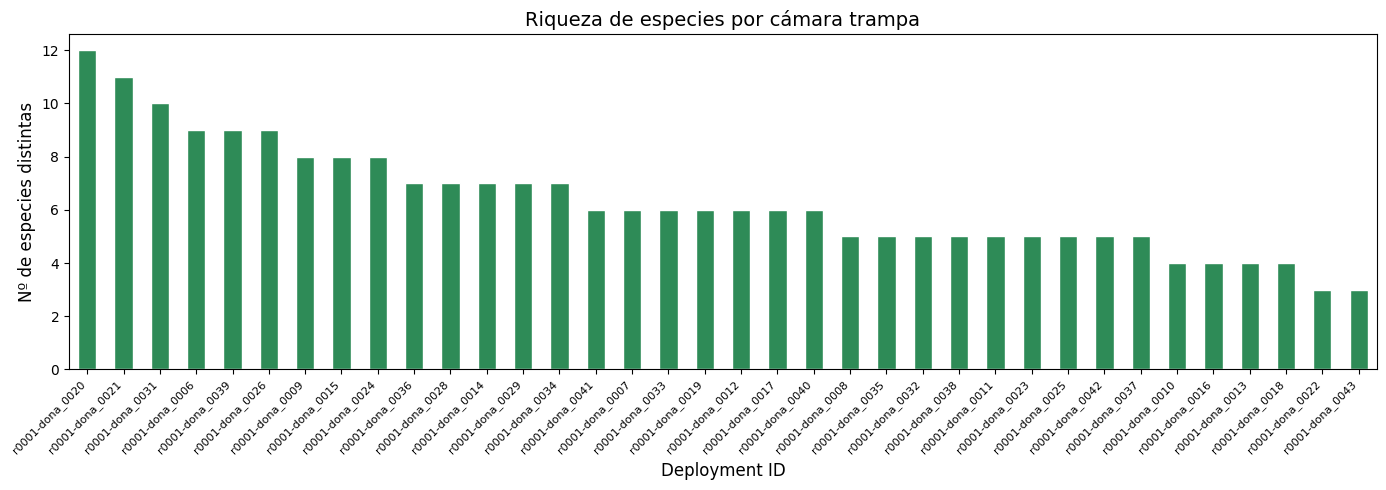

In [15]:
# Riqueza de especies por cámara
richness = (
    df[df['scientificName'].notna()]
    .groupby('deploymentID')['scientificName']
    .nunique()
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(14, 5))
richness.plot.bar(ax=ax, color='seagreen', edgecolor='white')
ax.set_ylabel('Nº de especies distintas')
ax.set_xlabel('Deployment ID')
ax.set_title('Riqueza de especies por cámara trampa')
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.tight_layout()
plt.show()

## 8. Especies destacadas 🐾

Un breve resumen de hallazgos interesantes.

In [16]:
# Resumen de especies relevantes
highlight = df[df['scientificName'].notna()].copy()

resumen = (
    highlight.groupby('nombre_comun')
    .agg(
        total_registros=('observationID', 'count'),
        conteo_medio=('count', 'mean'),
        conteo_max=('count', 'max'),
        confianza_media=('classificationProbability', 'mean'),
        confianza_min=('classificationProbability', 'min'),
        n_camaras=('deploymentID', 'nunique'),
    )
    .round(2)
    .sort_values('total_registros', ascending=False)
)

resumen

,total_registros,conteo_medio,conteo_max,confianza_media,confianza_min,n_camaras
nombre_comun,,,,,,
Cérvido (sin especificar),4618,1.37,6,0.68,0.50,32
Ciervo rojo,4183,1.64,6,0.74,0.50,30
Jabalí,3558,1.36,8,0.92,0.56,28
Vaca / Toro,2107,1.53,7,0.92,0.46,8
Gamo,874,1.40,6,0.70,0.50,23
Lepórido (liebre/conejo),518,1.29,4,0.70,0.50,11
Zorro rojo,474,1.00,1,0.89,0.50,21
Conejo europeo,174,1.45,3,0.61,0.50,7
Tejón europeo,144,1.00,1,0.84,0.50,10


In [17]:
# Nota sobre el Lince ibérico
lince = df[df['scientificName'] == 'Lynx pardinus']
print(f"🐱 Lince ibérico — registros totales: {len(lince)}")
print(f"   Cámaras donde se detectó: {lince['deploymentID'].nunique()}")
print(f"   Rango de confianza: {lince['classificationProbability'].min():.2f} – {lince['classificationProbability'].max():.2f}")
if len(lince) > 0:
    print(f"   Fechas: {lince['eventStart'].min().strftime('%Y-%m-%d')} a {lince['eventStart'].max().strftime('%Y-%m-%d')}")

🐱 Lince ibérico — registros totales: 12
   Cámaras donde se detectó: 1
   Rango de confianza: 0.71 – 1.00
   Fechas: 2020-11-04 a 2020-11-04


---
## Conclusiones principales

- **Ciervo rojo** (*Cervus elaphus*) y **Cérvidos** (sin especificar) son las especies más frecuentes.
- El **jabalí** (*Sus scrofa*) es la segunda especie más registrada.
- Se registran también **ganado doméstico** (vacas y caballos), habitual en Doñana.
- El **lince ibérico** aparece en un número muy reducido de registros — dato valioso para su conservación.
- La confianza de clasificación varía significativamente entre especies — los cérvidos sin especificar suelen tener menor confianza.
- La actividad presenta un claro **patrón crepuscular/nocturno** en la mayoría de las especies.